In [54]:
import cudf
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from cuml.metrics import confusion_matrix
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid
import kagglehub
import warnings
warnings.filterwarnings('ignore')

In [2]:
import cuml
cuml.set_global_output_type('cupy')

In [3]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    cm_np = cp.asnumpy(cm)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_np, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [4]:
def print_confusion_matrix(cm, title):
    cm_np = cp.asnumpy(cm)
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm_np[0,0]:6d}  {cm_np[0,1]:6d}")
    print(f"Fraud      {cm_np[1,0]:6d}  {cm_np[1,1]:6d}")

In [5]:
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

100%|██████████| 13.1M/13.1M [00:00<00:00, 248MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ealaxi/banksim1/versions/1


In [6]:
data = cudf.read_csv(path + '/bs140513_032310.csv')

In [7]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype('float32')

In [8]:
data['amount'] = data['amount'].astype('float32')
data['amount_thresh'] = cudf.Series('>3000', index=data.index)
data.loc[data['amount'] <= 500, 'amount_thresh'] = '0-500'
data.loc[(data['amount'] > 500) & (data['amount'] <= 1000), 'amount_thresh'] = '500-1000'
data.loc[(data['amount'] > 1000) & (data['amount'] <= 1500), 'amount_thresh'] = '1000-1500'
data.loc[(data['amount'] > 1500) & (data['amount'] <= 2000), 'amount_thresh'] = '1500-2000'
data.loc[(data['amount'] > 2000) & (data['amount'] <= 2500), 'amount_thresh'] = '2000-2500'
data.loc[(data['amount'] > 2500) & (data['amount'] <= 3000), 'amount_thresh'] = '2500-3000'

In [9]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = cp.arange(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = cp.arange(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = cp.arange(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = cp.arange(1, len(amount_thresh) + 1)

In [10]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [11]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [12]:
ohe = OneHotEncoder(sparse=False, handle_unknown='ignore')
ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
ohe_data = ohe.fit_transform(data[ohe_cols])
ohe_feature_names = ohe.get_feature_names(ohe_cols)
ohe_data = cudf.DataFrame(ohe_data, columns=ohe_feature_names)
data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)

In [13]:
le = LabelEncoder()
data['fraud'] = le.fit_transform(data['fraud'])

print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [14]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
scaled_data_big = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data_big)
pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

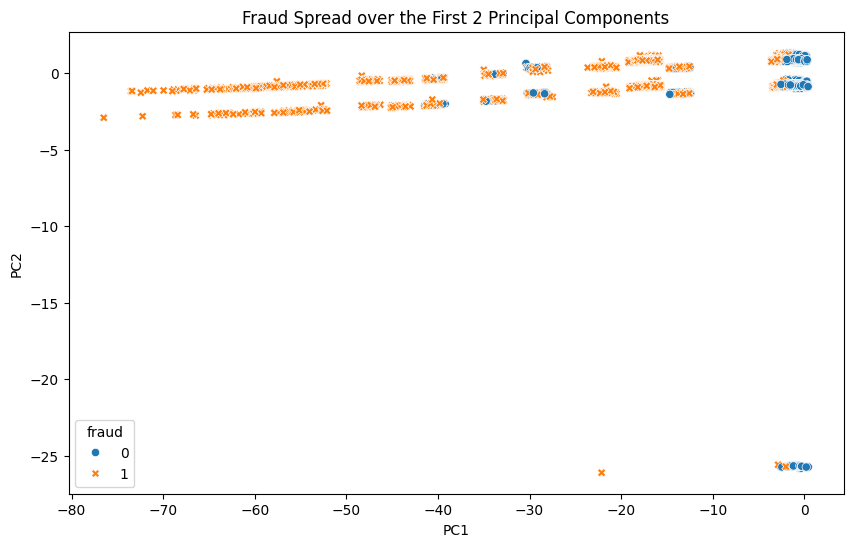

Explained variance ratio: [0.09855735 0.06097573]


In [15]:
pca_df_np = pca_df.to_pandas()
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df_np)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

print("Explained variance ratio:", cp.asnumpy(pca.explained_variance_ratio_))

In [16]:
X = data.drop('fraud', axis=1)
y = data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

In [48]:
sample_indices = cp.random.choice(scaled_data_big.shape[0], size=42949, replace=False)
scaled_data_sample = scaled_data_big[sample_indices]
y_sample = y[sample_indices]

In [49]:
import numpy as np


Parameters: {'eps': 0.3, 'min_samples': 5}, Silhouette Score: 0.9007


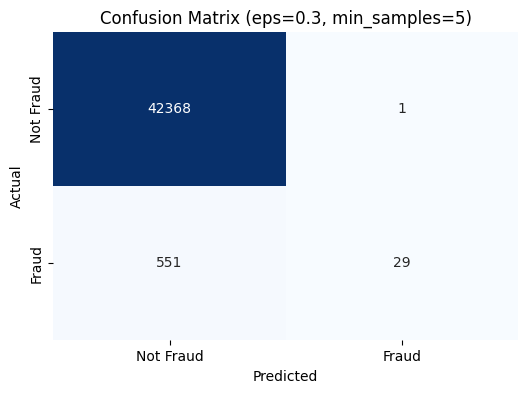

Confusion Matrix (eps=0.3, min_samples=5):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42368       1
Fraud         551      29
Parameters: {'eps': 0.3, 'min_samples': 10}, Silhouette Score: 0.8881


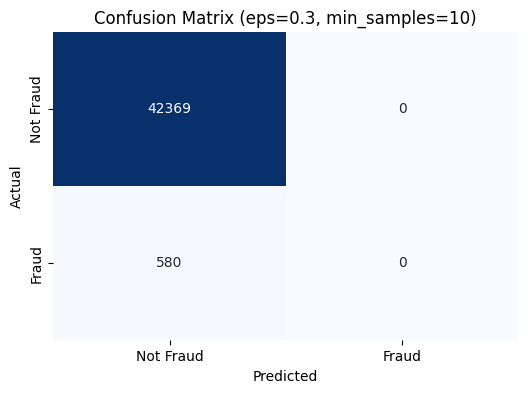

Confusion Matrix (eps=0.3, min_samples=10):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 0.3, 'min_samples': 15}, Silhouette Score: 0.8800


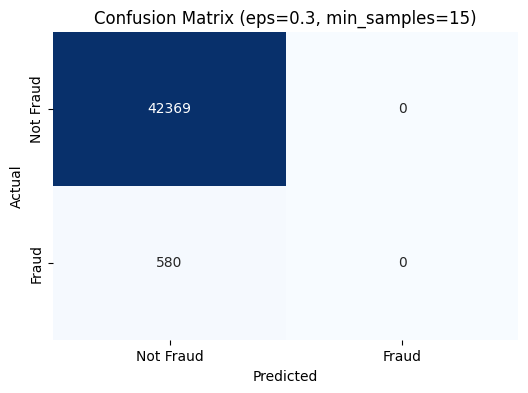

Confusion Matrix (eps=0.3, min_samples=15):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 0.3, 'min_samples': 20}, Silhouette Score: 0.8725


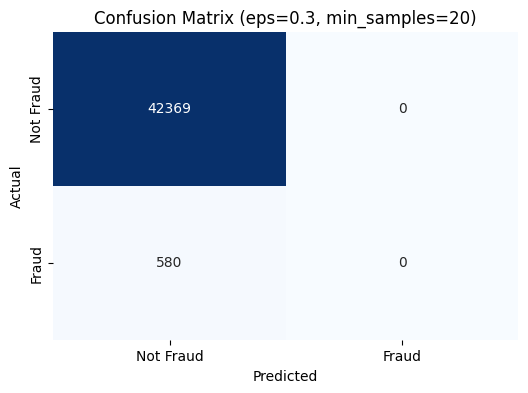

Confusion Matrix (eps=0.3, min_samples=20):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 0.5, 'min_samples': 5}, Silhouette Score: 0.9063


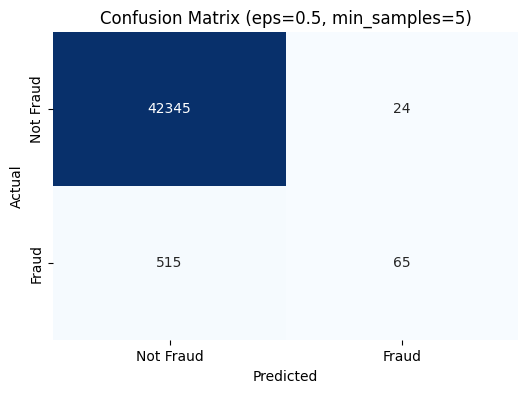

Confusion Matrix (eps=0.5, min_samples=5):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42345      24
Fraud         515      65
Parameters: {'eps': 0.5, 'min_samples': 10}, Silhouette Score: 0.8973


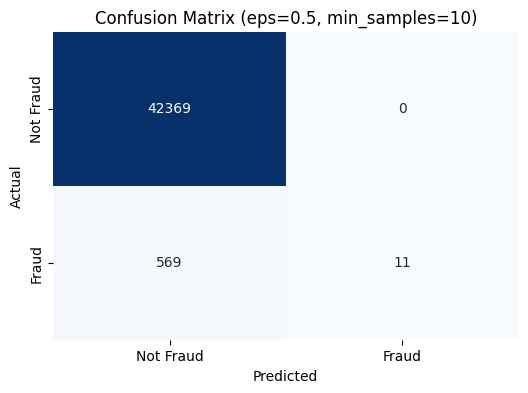

Confusion Matrix (eps=0.5, min_samples=10):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         569      11
Parameters: {'eps': 0.5, 'min_samples': 15}, Silhouette Score: 0.8911


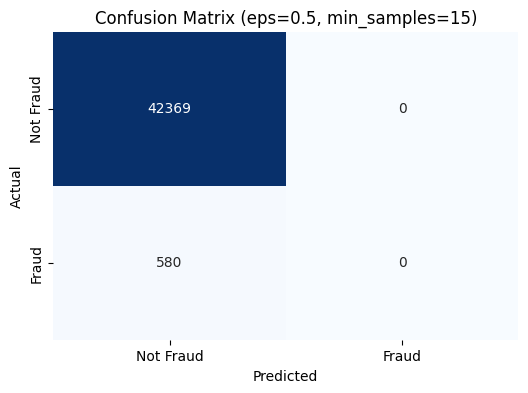

Confusion Matrix (eps=0.5, min_samples=15):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 0.5, 'min_samples': 20}, Silhouette Score: 0.8845


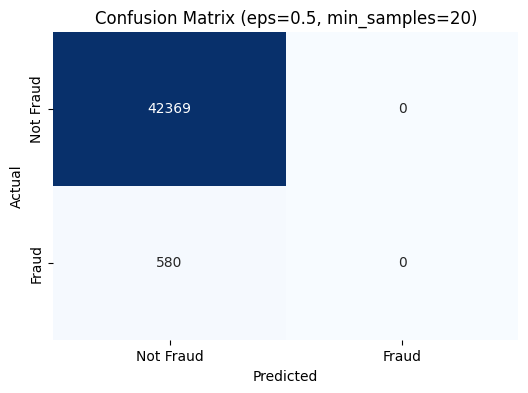

Confusion Matrix (eps=0.5, min_samples=20):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 0.7, 'min_samples': 5}, Silhouette Score: 0.9100


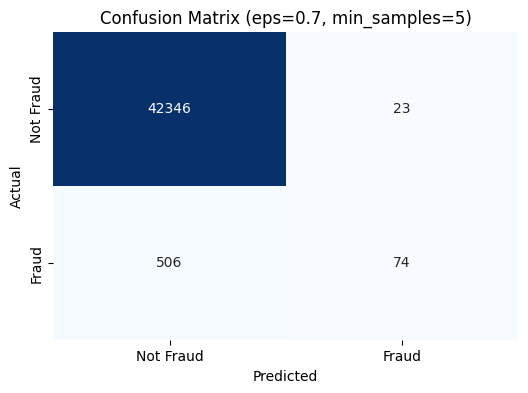

Confusion Matrix (eps=0.7, min_samples=5):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         506      74
Parameters: {'eps': 0.7, 'min_samples': 10}, Silhouette Score: 0.8999


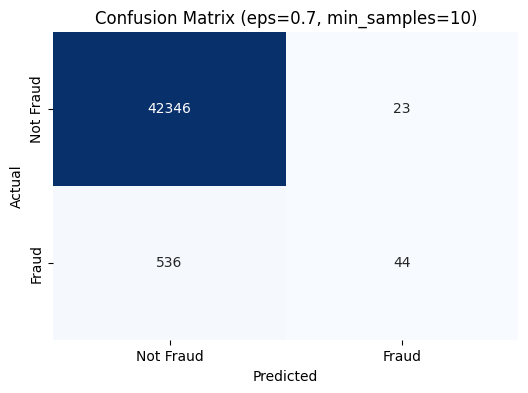

Confusion Matrix (eps=0.7, min_samples=10):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         536      44
Parameters: {'eps': 0.7, 'min_samples': 15}, Silhouette Score: 0.8935


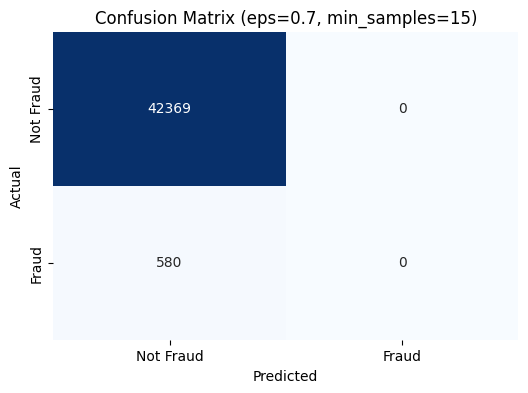

Confusion Matrix (eps=0.7, min_samples=15):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 0.7, 'min_samples': 20}, Silhouette Score: 0.8887


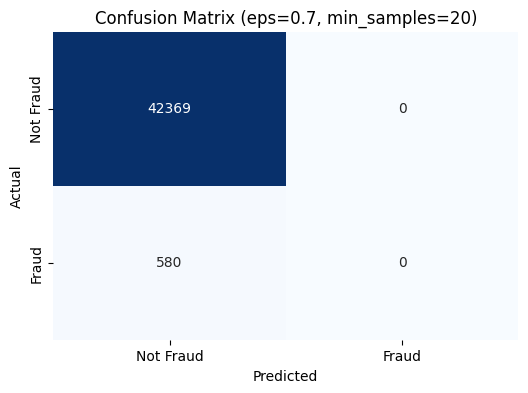

Confusion Matrix (eps=0.7, min_samples=20):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42369       0
Fraud         580       0
Parameters: {'eps': 1.0, 'min_samples': 5}, Silhouette Score: 0.9124


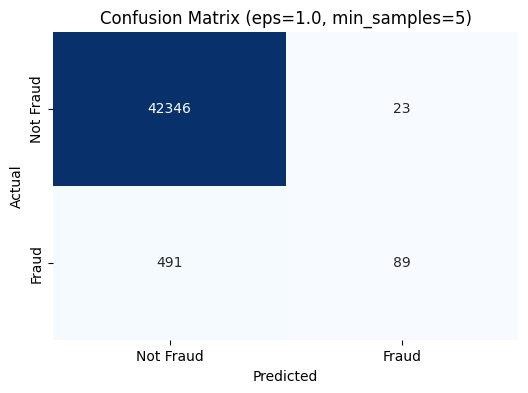

Confusion Matrix (eps=1.0, min_samples=5):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         491      89
Parameters: {'eps': 1.0, 'min_samples': 10}, Silhouette Score: 0.9039


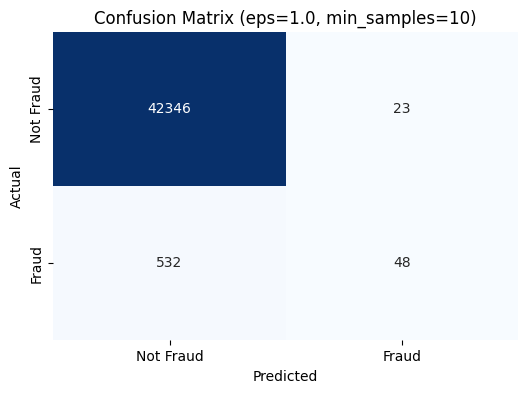

Confusion Matrix (eps=1.0, min_samples=10):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         532      48
Parameters: {'eps': 1.0, 'min_samples': 15}, Silhouette Score: 0.8979


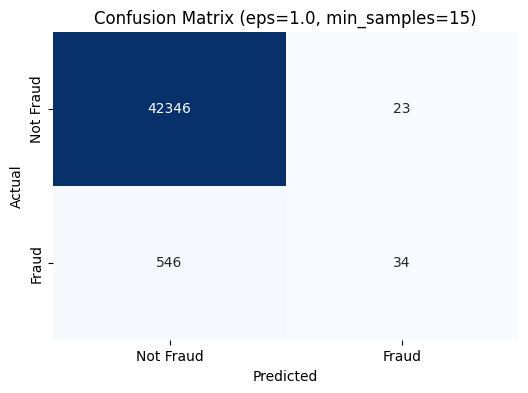

Confusion Matrix (eps=1.0, min_samples=15):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         546      34
Parameters: {'eps': 1.0, 'min_samples': 20}, Silhouette Score: 0.8921


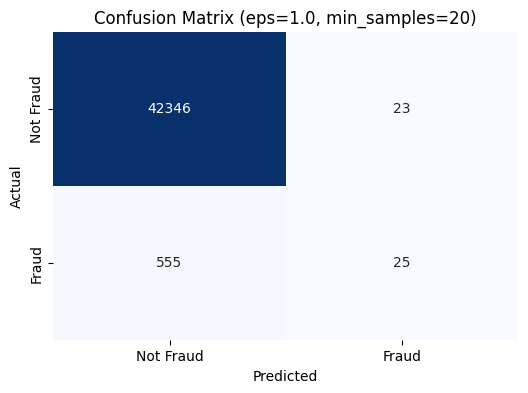

Confusion Matrix (eps=1.0, min_samples=20):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         555      25
Parameters: {'eps': 1.5, 'min_samples': 5}, Silhouette Score: 0.9140


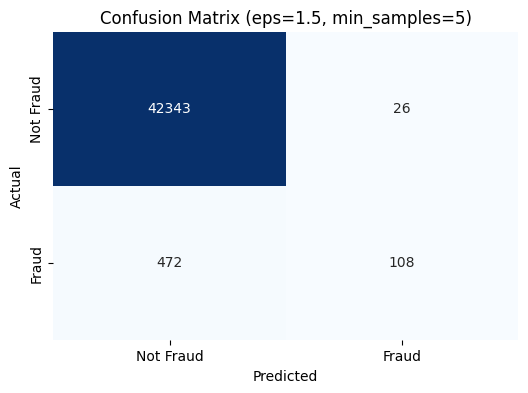

Confusion Matrix (eps=1.5, min_samples=5):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42343      26
Fraud         472     108
Parameters: {'eps': 1.5, 'min_samples': 10}, Silhouette Score: 0.9059


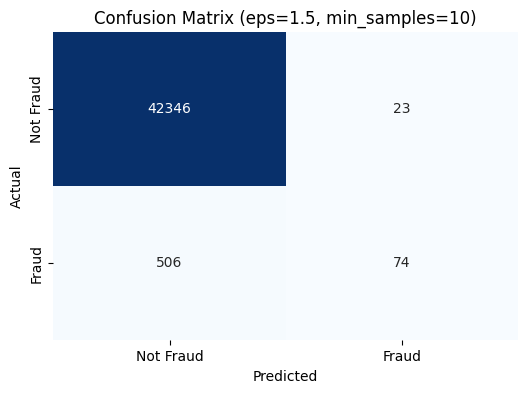

Confusion Matrix (eps=1.5, min_samples=10):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         506      74
Parameters: {'eps': 1.5, 'min_samples': 15}, Silhouette Score: 0.8995


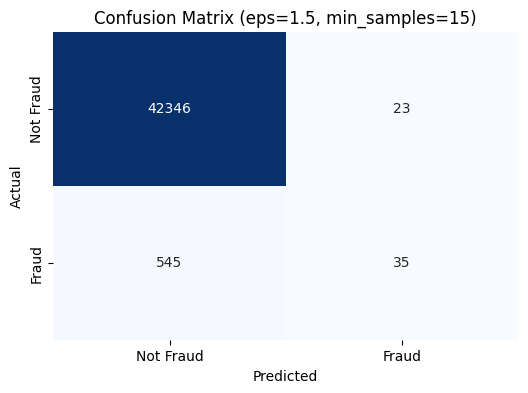

Confusion Matrix (eps=1.5, min_samples=15):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         545      35
Parameters: {'eps': 1.5, 'min_samples': 20}, Silhouette Score: 0.8943


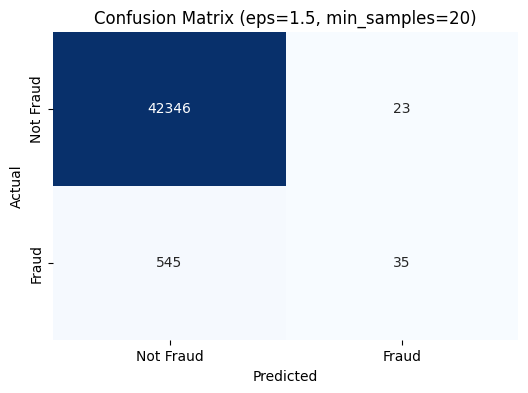

Confusion Matrix (eps=1.5, min_samples=20):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   42346      23
Fraud         545      35

Best Parameters: {'eps': 1.5, 'min_samples': 5}
Best Silhouette Score: 0.9140366


In [50]:
param_grid = {
    'eps': [0.3, 0.5, 0.7, 1.0, 1.5],
    'min_samples': [5, 10, 15, 20]
}

best_score = -1
best_params = None
best_labels = None

for params in ParameterGrid(param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(scaled_data_sample)

    if len(cp.unique(labels)) > 1:  # Silhouette score requires at least 2 clusters
        score = silhouette_score(scaled_data_sample.get(), labels.get())
        print(f"Parameters: {params}, Silhouette Score: {score:.4f}")

        # Create temporary DataFrame with cluster labels
        temp_data = cudf.DataFrame({
            'dbscan_cluster': labels.astype('int32'),
            'true_label': y_sample.astype('int32')
        })

        # Dynamically map clusters to fraud/not fraud based on majority voting
        cluster_mapping = {}
        unique_clusters = cp.unique(labels).get()

        for cluster in unique_clusters:
            if cluster != -1:
                mask = temp_data['dbscan_cluster'] == cluster
                majority_label = temp_data[mask]['true_label'].mode().iloc[0].item()
                cluster_mapping[int(cluster)] = int(majority_label)

        # Create mapped labels column
        temp_data['unusual_behaviour'] = 0
        for cluster, label in cluster_mapping.items():
            temp_data.loc[temp_data['dbscan_cluster'] == cluster, 'unusual_behaviour'] = label

        # Convert to numpy arrays with explicit dtype
        y_true = np.array(
            y_sample.astype('int32').values_host if hasattr(y_sample, 'values_host')
            else y_sample.astype('int32').to_numpy(),
            dtype='int32'
        )
        y_pred = np.array(
            temp_data['unusual_behaviour'].astype('int32').values_host
            if hasattr(temp_data['unusual_behaviour'], 'values_host')
            else temp_data['unusual_behaviour'].astype('int32').to_numpy(),
            dtype='int32'
        )

        # Compute confusion matrix using sklearn (more stable with numpy inputs)
        from sklearn.metrics import confusion_matrix as sk_confusion_matrix
        cm = sk_confusion_matrix(y_true, y_pred, labels=[0, 1])

        if np.any(np.isnan(cm)) or np.any(np.isinf(cm)):
            print(f"Warning: Confusion matrix for {params} contains NaN or inf values, skipping display.")
        else:
            draw_confusion_matrix(cm, title=f'Confusion Matrix (eps={params["eps"]}, min_samples={params["min_samples"]})')
            print_confusion_matrix(cm, f"Confusion Matrix (eps={params['eps']}, min_samples={params['min_samples']})")

        if score > best_score:
            best_score = score
            best_params = params
            best_labels = labels

print("\nBest Parameters:", best_params)
print("Best Silhouette Score:", best_score)

In [ ]:
dbscan = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
dbscan_labels = dbscan.fit_predict(scaled_data_big)

In [ ]:
dbscan_data = cudf.DataFrame(scaled_data_big, columns=pca_cols)
dbscan_data['cluster'] = dbscan_labels
dbscan_data_final = data.copy()
dbscan_data_final['dbscan_cluster'] = dbscan_labels
dbscan_data_final['unusual_behaviour'] = cp.where(dbscan_data_final['dbscan_cluster'] == 0, 1, 0)  #

In [ ]:
cm_dbscan = confusion_matrix(dbscan_data_final['fraud'], dbscan_data_final['unusual_behaviour'], labels=[0, 1])
draw_confusion_matrix(cm_dbscan, title='DBSCAN Confusion Matrix (Best Parameters)')
print_confusion_matrix(cm_dbscan, 'DBSCAN Confusion Matrix (Best Parameters)')

In [55]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

refined_param_grid = {
    'eps': [1.3, 1.5, 1.7],  # Focused around best performing range
    'min_samples': [3, 5, 7]   # Test lower min_samples values
}

# Initialize tracking variables
best_score = -1
best_params = None
best_labels = None
results = []

# Custom scoring function for fraud detection
def fraud_scorer(y_true, y_pred):
    return f1_score(y_true, y_pred, average='binary', pos_label=1)

# Main grid search loop
for params in ParameterGrid(refined_param_grid):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(scaled_data_sample)

    if len(cp.unique(labels)) > 1:  # Need at least 2 clusters for evaluation
        # Create temporary DataFrame
        temp_data = cudf.DataFrame({
            'dbscan_cluster': labels.astype('int32'),
            'true_label': y_sample.astype('int32')
        })

        # Dynamic cluster mapping with adjustable fraud threshold
        cluster_mapping = {}
        unique_clusters = cp.unique(labels).get()

        for cluster in unique_clusters:
            if cluster != -1:
                mask = temp_data['dbscan_cluster'] == cluster
                fraud_ratio = temp_data[mask]['true_label'].mean()
                # More aggressive threshold (10% fraud in cluster)
                cluster_mapping[int(cluster)] = 1 if fraud_ratio > 0.10 else 0

        # Apply mapping
        temp_data['predicted_label'] = 0
        for cluster, label in cluster_mapping.items():
            temp_data.loc[temp_data['dbscan_cluster'] == cluster, 'predicted_label'] = label

        # Convert to numpy for sklearn metrics
        y_true = y_sample.astype('int32').to_numpy()
        y_pred = temp_data['predicted_label'].astype('int32').to_numpy()

        # Calculate metrics
        sil_score = silhouette_score(scaled_data_sample.get(), labels.get())
        f1 = fraud_scorer(y_true, y_pred)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

        # Store results
        results.append({
            'params': params,
            'silhouette': sil_score,
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'confusion_matrix': cm
        })

        print(f"Parameters: {params}")
        print(f"Silhouette: {sil_score:.4f}, F1: {f1:.4f}, Precision: {precision:.2%}, Recall: {recall:.2%}")
        print_confusion_matrix(cm, f"Confusion Matrix (eps={params['eps']}, min_samples={params['min_samples']})")

        # Update best model based on F1 score
        if f1 > best_score:
            best_score = f1
            best_params = params
            best_labels = labels

# Results Analysis
print("\n=== Best Model ===")
best_result = next(r for r in results if r['params'] == best_params)
print(f"Parameters: {best_params}")
print(f"F1 Score: {best_result['f1']:.4f}")
print(f"Precision: {best_result['precision']:.2%}")
print(f"Recall: {best_result['recall']:.2%}")
print_confusion_matrix(best_result['confusion_matrix'], "Best Model Confusion Matrix")

# Visualization


Parameters: {'eps': 1.3, 'min_samples': 3}
Silhouette: 0.9158, F1: 0.4248, Precision: 34.88%, Recall: 54.31%
Confusion Matrix (eps=1.3, min_samples=3):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   41781     588
Fraud         265     315
Parameters: {'eps': 1.3, 'min_samples': 5}
Silhouette: 0.9133, F1: 0.3639, Precision: 30.79%, Recall: 44.48%
Confusion Matrix (eps=1.3, min_samples=5):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   41789     580
Fraud         322     258
Parameters: {'eps': 1.3, 'min_samples': 7}
Silhouette: 0.9089, F1: 0.3306, Precision: 28.90%, Recall: 38.62%
Confusion Matrix (eps=1.3, min_samples=7):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   41818     551
Fraud         356     224
Parameters: {'eps': 1.5, 'min_samples': 3}
Silhouette: 0.9160, F1: 0.4309, Precision: 35.06%, Recall: 55.86%
Confusion Matrix (eps=1.5, min_samples=3):
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   41769     600
Fr

TypeError: string indices must be integers, not 'str'

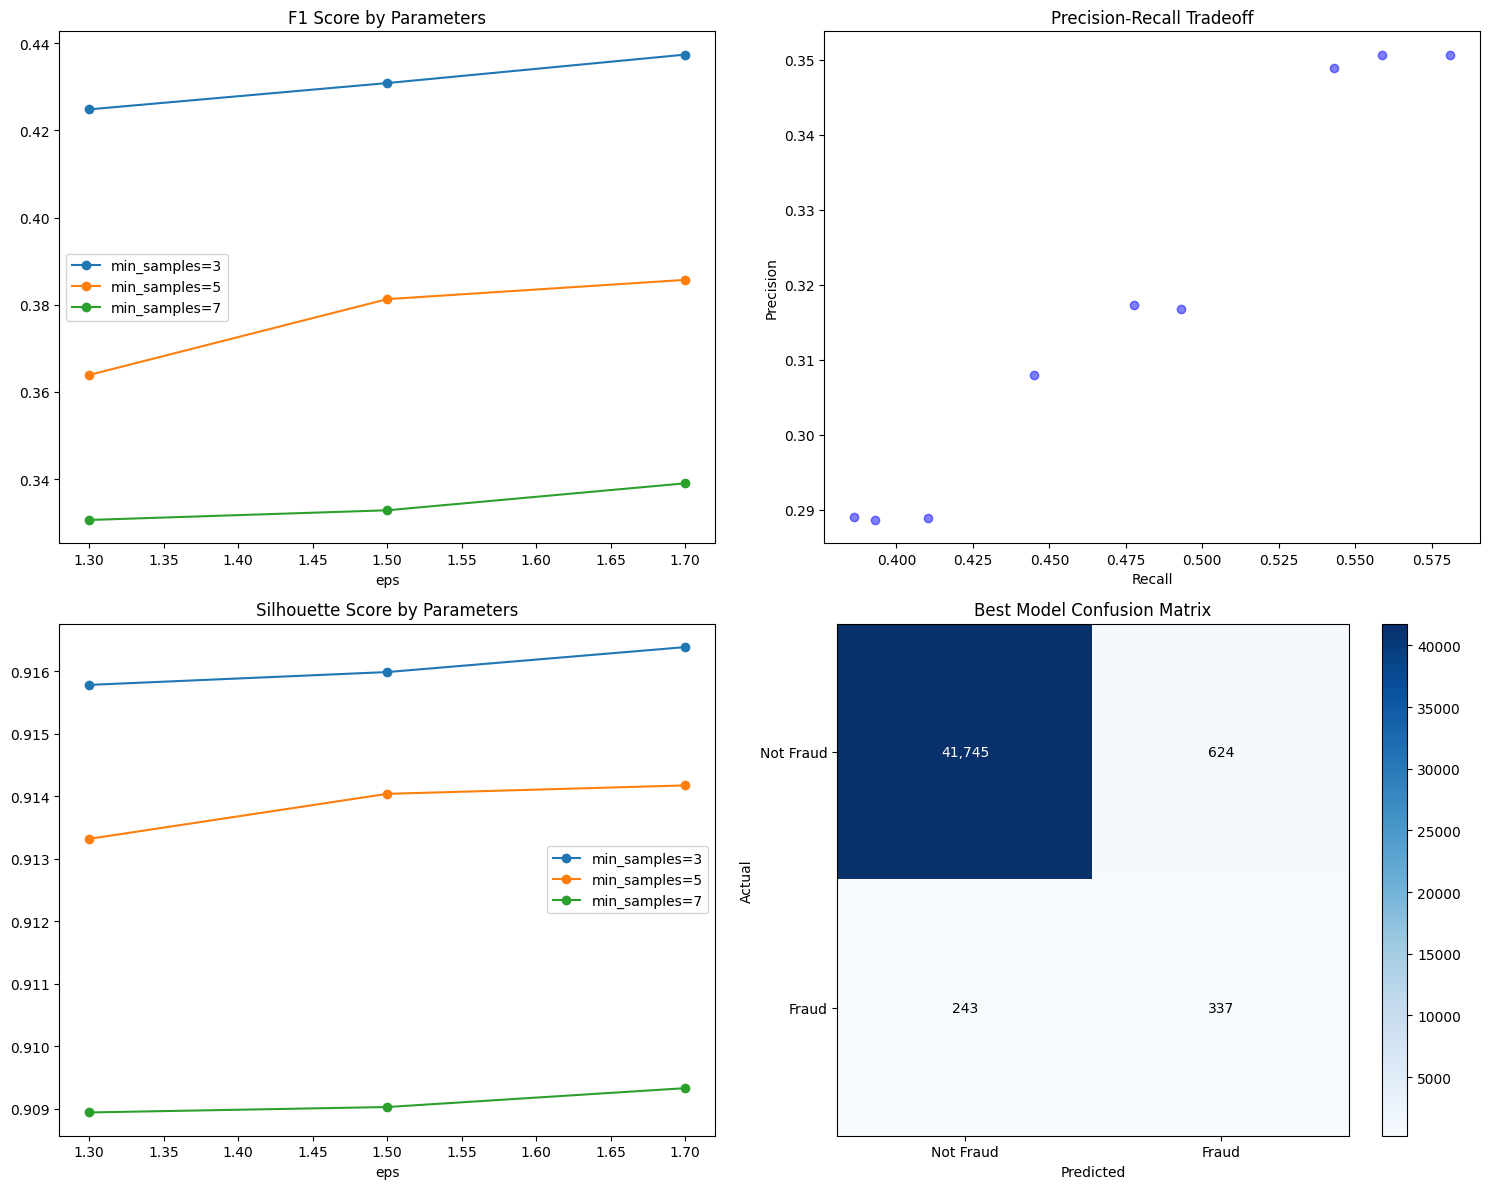

In [58]:
def plot_metrics(results, param_grid):
    # Access parameter combinations as dictionaries using product_dict
    param_combinations = list(ParameterGrid(param_grid))

    eps_values = sorted(list(set(p['eps'] for p in param_combinations)))
    min_samples_values = sorted(list(set(p['min_samples'] for p in param_combinations)))

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # F1 Scores
    for ms in min_samples_values:
        f1_scores = [r['f1'] for r in results if r['params']['min_samples'] == ms]
        axes[0,0].plot(eps_values, f1_scores, 'o-', label=f'min_samples={ms}')
    axes[0,0].set_title('F1 Score by Parameters')
    axes[0,0].set_xlabel('eps')
    axes[0,0].legend()

    # Precision-Recall Tradeoff
    precisions = [r['precision'] for r in results]
    recalls = [r['recall'] for r in results]
    axes[0,1].scatter(recalls, precisions, c='blue', alpha=0.5)
    axes[0,1].set_title('Precision-Recall Tradeoff')
    axes[0,1].set_xlabel('Recall')
    axes[0,1].set_ylabel('Precision')

    # Silhouette Scores
    for ms in min_samples_values:
        sil_scores = [r['silhouette'] for r in results if r['params']['min_samples'] == ms]
        axes[1,0].plot(eps_values, sil_scores, 'o-', label=f'min_samples={ms}')
    axes[1,0].set_title('Silhouette Score by Parameters')
    axes[1,0].set_xlabel('eps')
    axes[1,0].legend()

    # Confusion Matrix Heatmap (Best Model)
# Enhanced confusion matrix visualization with numbers
    im = axes[1,1].imshow(best_result['confusion_matrix'], cmap='Blues')
    axes[1,1].set_title('Best Model Confusion Matrix')

    # Add text annotations
    for i in range(best_result['confusion_matrix'].shape[0]):
        for j in range(best_result['confusion_matrix'].shape[1]):
            axes[1,1].text(j, i, f"{best_result['confusion_matrix'][i, j]:,}",
                          ha="center", va="center",
                          color="white" if best_result['confusion_matrix'][i, j] > best_result['confusion_matrix'].max()/2 else "black")

    # Add axis labels
    axes[1,1].set_xticks([0, 1])
    axes[1,1].set_yticks([0, 1])
    axes[1,1].set_xticklabels(['Not Fraud', 'Fraud'])
    axes[1,1].set_yticklabels(['Not Fraud', 'Fraud'])
    axes[1,1].set_xlabel('Predicted')
    axes[1,1].set_ylabel('Actual')

    plt.colorbar(im, ax=axes[1,1])

    plt.tight_layout()
    plt.show()

plot_metrics(results, refined_param_grid)

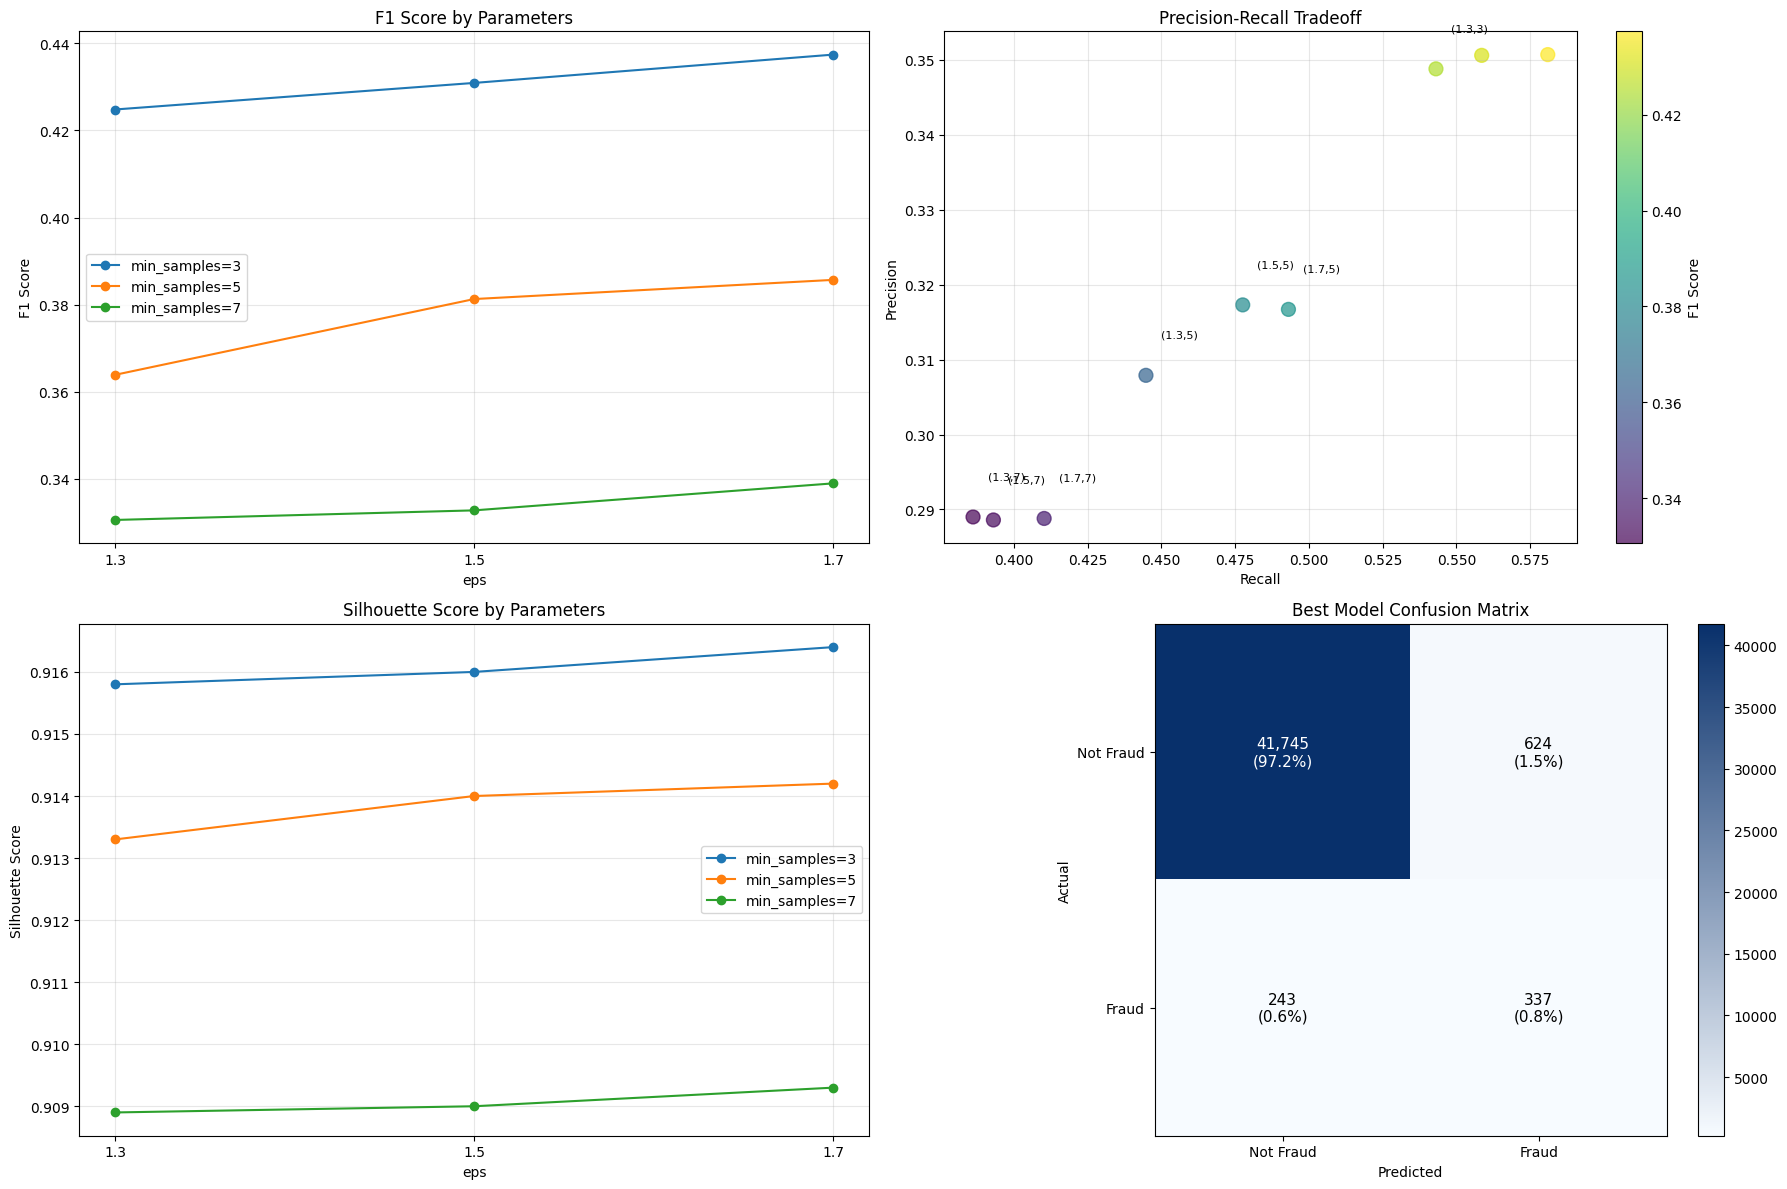


=== Best Model ===
Parameters: eps=1.7, min_samples=3
F1 Score: 0.4374
Precision: 35.07%
Recall: 58.10%

Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud   41745     624
Fraud         243     337


In [60]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.model_selection import ParameterGrid
from cuml.cluster import DBSCAN
from cuml.metrics import confusion_matrix as cuml_confusion_matrix
from sklearn.metrics import silhouette_score
import cudf
import cupy as cp

# Your results data
results = [
    {'params': {'eps': 1.3, 'min_samples': 3}, 'silhouette': 0.9158, 'f1': 0.4248, 'precision': 0.3488, 'recall': 0.5431, 'confusion_matrix': np.array([[41781, 588], [265, 315]])},
    {'params': {'eps': 1.3, 'min_samples': 5}, 'silhouette': 0.9133, 'f1': 0.3639, 'precision': 0.3079, 'recall': 0.4448, 'confusion_matrix': np.array([[41789, 580], [322, 258]])},
    {'params': {'eps': 1.3, 'min_samples': 7}, 'silhouette': 0.9089, 'f1': 0.3306, 'precision': 0.2890, 'recall': 0.3862, 'confusion_matrix': np.array([[41818, 551], [356, 224]])},
    {'params': {'eps': 1.5, 'min_samples': 3}, 'silhouette': 0.9160, 'f1': 0.4309, 'precision': 0.3506, 'recall': 0.5586, 'confusion_matrix': np.array([[41769, 600], [256, 324]])},
    {'params': {'eps': 1.5, 'min_samples': 5}, 'silhouette': 0.9140, 'f1': 0.3813, 'precision': 0.3173, 'recall': 0.4776, 'confusion_matrix': np.array([[41773, 596], [303, 277]])},
    {'params': {'eps': 1.5, 'min_samples': 7}, 'silhouette': 0.9090, 'f1': 0.3328, 'precision': 0.2886, 'recall': 0.3931, 'confusion_matrix': np.array([[41807, 562], [352, 228]])},
    {'params': {'eps': 1.7, 'min_samples': 3}, 'silhouette': 0.9164, 'f1': 0.4374, 'precision': 0.3507, 'recall': 0.5810, 'confusion_matrix': np.array([[41745, 624], [243, 337]])},
    {'params': {'eps': 1.7, 'min_samples': 5}, 'silhouette': 0.9142, 'f1': 0.3857, 'precision': 0.3167, 'recall': 0.4931, 'confusion_matrix': np.array([[41752, 617], [294, 286]])},
    {'params': {'eps': 1.7, 'min_samples': 7}, 'silhouette': 0.9093, 'f1': 0.3390, 'precision': 0.2888, 'recall': 0.4103, 'confusion_matrix': np.array([[41783, 586], [342, 238]])}
]

# Find best model
best_result = max(results, key=lambda x: x['f1'])

# Create visualization
plt.figure(figsize=(18, 12))

# Custom colormap
cmap = LinearSegmentedColormap.from_list('custom_blue', ['#f7fbff', '#08306b'])

# 1. F1 Score by Parameters
plt.subplot(2, 2, 1)
for min_samples in [3, 5, 7]:
    eps_values = []
    f1_scores = []
    for r in results:
        if r['params']['min_samples'] == min_samples:
            eps_values.append(r['params']['eps'])
            f1_scores.append(r['f1'])
    plt.plot(eps_values, f1_scores, 'o-', label=f'min_samples={min_samples}')
plt.title('F1 Score by Parameters', fontsize=12)
plt.xlabel('eps', fontsize=10)
plt.ylabel('F1 Score', fontsize=10)
plt.xticks([1.3, 1.5, 1.7])
plt.grid(True, alpha=0.3)
plt.legend()

# 2. Precision-Recall Tradeoff
plt.subplot(2, 2, 2)
precisions = [r['precision'] for r in results]
recalls = [r['recall'] for r in results]
colors = [r['f1'] for r in results]
sc = plt.scatter(recalls, precisions, c=colors, cmap='viridis', alpha=0.7, s=100)
plt.colorbar(sc, label='F1 Score')
plt.title('Precision-Recall Tradeoff', fontsize=12)
plt.xlabel('Recall', fontsize=10)
plt.ylabel('Precision', fontsize=10)
plt.grid(True, alpha=0.3)

# Annotate points with parameters
for i, r in enumerate(results):
    plt.annotate(f"({r['params']['eps']},{r['params']['min_samples']})",
                (recalls[i]+0.005, precisions[i]+0.005),
                fontsize=8)

# 3. Silhouette Score by Parameters
plt.subplot(2, 2, 3)
for min_samples in [3, 5, 7]:
    eps_values = []
    sil_scores = []
    for r in results:
        if r['params']['min_samples'] == min_samples:
            eps_values.append(r['params']['eps'])
            sil_scores.append(r['silhouette'])
    plt.plot(eps_values, sil_scores, 'o-', label=f'min_samples={min_samples}')
plt.title('Silhouette Score by Parameters', fontsize=12)
plt.xlabel('eps', fontsize=10)
plt.ylabel('Silhouette Score', fontsize=10)
plt.xticks([1.3, 1.5, 1.7])
plt.grid(True, alpha=0.3)
plt.legend()

# 4. Best Model Confusion Matrix
plt.subplot(2, 2, 4)
cm = best_result['confusion_matrix']
im = plt.imshow(cm, cmap=cmap)

# Add text annotations with proper formatting
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, f"{cm[i, j]:,}\n({cm[i, j]/cm.sum()*100:.1f}%)",
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=11)

plt.title('Best Model Confusion Matrix', fontsize=12)
plt.xticks([0, 1], ['Not Fraud', 'Fraud'], fontsize=10)
plt.yticks([0, 1], ['Not Fraud', 'Fraud'], fontsize=10)
plt.xlabel('Predicted', fontsize=10)
plt.ylabel('Actual', fontsize=10)
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# Print best model summary
print("\n=== Best Model ===")
print(f"Parameters: eps={best_result['params']['eps']}, min_samples={best_result['params']['min_samples']}")
print(f"F1 Score: {best_result['f1']:.4f}")
print(f"Precision: {best_result['precision']:.2%}")
print(f"Recall: {best_result['recall']:.2%}")
print("\nConfusion Matrix:")
print(f"         Predicted")
print(f"         Not Fraud  Fraud")
print(f"Actual")
print(f"Not Fraud {best_result['confusion_matrix'][0, 0]:>7} {best_result['confusion_matrix'][0, 1]:>7}")
print(f"Fraud     {best_result['confusion_matrix'][1, 0]:>7} {best_result['confusion_matrix'][1, 1]:>7}")

In [ ]:
plot_metrics(results, refined_param_grid)